In [9]:
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import math

# Grasshopper / Taxicab Spin Optimization

This project studies a discrete version of the *grasshopper problem* on an $(n \times n)$ grid using the taxicab metric.

## Goal

Arrange a fixed number of lawn cells (spins $= 1$) on an $n \times n$ square grid so as to maximize the probability that a grasshopper that lands on a lawn cell and then jumps a fixed taxicab distance $d$ will land on a lawn cell again.

---

## Grid and Distance

- Grid points: Integer coordinates $(x,y)$ where $x,y \in \{0,1,\dots,n-1\}$
- Taxicab distance: 
  $$ \text{dist}\big((x_1,y_1),(x_2,y_2)\big) = |x_1-x_2| + |y_1-y_2| $$
- Valid jump: Any unordered pair of points with $\text{dist} = d$

---

## Success Probability

Let:
- $\text{total\_jumps}$ = number of all possible jumps of distance $d$
- $\text{success}$ = number of jumps where both endpoints are lawn

Success probability: 
$$ P = \frac{\text{success}}{\text{total\_jumps}} $$

Energy is proportional to $-\text{success}$:
$$ E \propto -\text{success} $$

---

## Energy Function

We define the energy as:
$$ E = \frac{\alpha}{2} \sum_{i} \sum_{j \in \mathcal{N}_d(i)} \delta(s_i,1)\,\delta(s_j,1) $$

where:
- $s_i \in \{0,1\}$: spin at site $i$ (1=lawn, 0=empty)
- $\mathcal{N}_d(i)$: neighbors of $i$ at distance $d$
- $\alpha$: prefactor (scaling constant)
- $\delta(s,1)$: Kronecker delta (1 if $s=1$, 0 otherwise)

**Interpretation**: Lower $E$ → more successful jumps → higher grasshopper success.

---

## Energy Updates ($\Delta E$)

When swapping:
- occupied site $a$ ($s_a = 1$) with
- empty site $b$ ($s_b = 0$)

Energy change:
$$ \Delta E = \alpha \times (N_b - N_a) $$

where:
- $N_a$ = number of occupied neighbors of $a$ at distance $d$
- $N_b$ = number of occupied neighbors of $b$ at distance $d$

**Special case**: If $a$ and $b$ are distance $d$ apart, exclude $a$ from $N_b$.

This allows $O(d)$ updates instead of $O(n^2)$.

---

## Implementation Notes

### Normalization
We use raw energy (success count) rather than normalized probability to avoid unnecessary divisions.

### Monte Carlo Optimization
- **Metropolis algorithm** with temperature $T$
- Accept swaps with probability $\min(1, \exp(-\Delta E/T))$
- Lower $T$ → more greedy, higher $T$ → more exploratory

### Greedy Optimization ($T=0$)
- Only accept swaps with $\Delta E \le 0$
- Faster but can get stuck in local minima
- Useful for final refinement

---

## Neighbor Precomputation

For performance, precompute all neighbor relationships:
- Store as dictionary: `{(x,y): [(neighbor coordinates at distance d)]}`
- Avoids repeated distance calculations during simulation
- Memory cost: $O(n^2 \times \text{avg\_neighbors})$

---

## Algorithm Steps

1. **Initialize**:
   - Create random configuration with fixed number of lawns
   - Precompute neighbor lists for all sites

2. **Optimize**:
   - Randomly select occupied site $a$ and empty site $b$
   - Compute $\Delta E = \alpha(N_b - N_a)$
   - Accept/reject using Metropolis criterion
   - Update configuration if accepted

3. **Measure**:
   - Track energy vs iteration
   - Record acceptance rate
   - Save best configuration found

---

## Expected Patterns

### Small $d$ (< n/3):
- Lawns form dense clusters
- High local success probability

### Large $d$ (> 2n/3):
- Lawns spread evenly
- May show periodic arrangements

### Intermediate $d$:
- Balance between clustering and spreading
- Most interesting optimization challenge

---

Return all grid locations at taxicab (Manhattan) distance exactly d from $(x,y)$
on an $(n \times n)$ grid. 
    
The results are returned as two 1D numpy arrays (rows, cols)
so that grid[rows, cols] indexes those points.


      Metropolis Tests       

--- Test 1: Reject uphill move (ΔE > 0, T = 0) ---
ones before : [(0, 0), (2, 1), (2, 2), (2, 3)]
zeros before: [(0, 1), (0, 2), (0, 3), (0, 4), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (2, 0), (2, 4), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
ΔE = 2.0
accepted: True
spins unchanged: False
FAIL

--- Test 2: Accept flat move (ΔE = 0) ---
ones before : [(1, 1)]
zeros before: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 0), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
ΔE = 0.0
accepted: True
spins changed: True
PASS

All Metropolis tests completed.



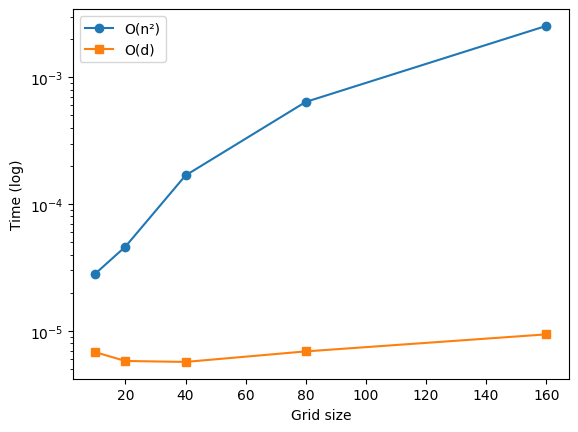

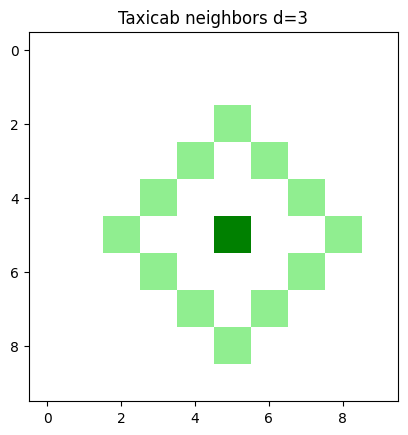

In [10]:
# Taxicab Neighbors (O(n^2)) - Original

def taxicab_neighbors(n, x, y, d):
    rows, cols = [], []
    for i in range(n):
        for j in range(n):
            if abs(i - x) + abs(j - y) == d:
                rows.append(i)
                cols.append(j)
    return np.array(rows), np.array(cols)


# Taxicab Neighbors (O(d)) - Explicit

def taxicab_neighbors_explicit(n, x, y, d):
    rows, cols = [], []
    for dx in range(-d, d + 1):
        dy = d - abs(dx)

        i1, j1 = x + dx, y + dy
        i2, j2 = x + dx, y - dy

        if 0 <= i1 < n and 0 <= j1 < n:
            rows.append(i1); cols.append(j1)

        if dy != 0 and 0 <= i2 < n and 0 <= j2 < n:
            rows.append(i2); cols.append(j2)

    return np.array(rows), np.array(cols)


# Precompute Neighbors (For Metropolis Only)

def precompute_taxicab_neighbors(n, d):
    """
    Precompute neighbors once to avoid repeated taxicab calls
    during Metropolis updates.
    """
    neighbors = {}
    for i in range(n):
        for j in range(n):
            r, c = taxicab_neighbors_explicit(n, i, j, d)
            neighbors[(i, j)] = list(zip(r, c))
    return neighbors


# Energy

def energy(grid, d=1, prefactor=1.0):
    n = grid.shape[0]
    occ = np.argwhere(grid == 1)

    total = 0
    for i, j in occ:
        r, c = taxicab_neighbors_explicit(n, i, j, d)
        total += np.sum(grid[r, c])

    return prefactor * total / 2


# Delta Energy

def delta_energy_swap(grid, d, prefactor, a, b):
    ax, ay = a
    bx, by = b

    n = grid.shape[0]

    Na = 0
    for i, j in zip(*taxicab_neighbors_explicit(n, ax, ay, d)):
        Na += grid[i, j]

    Nb = 0
    for i, j in zip(*taxicab_neighbors_explicit(n, bx, by, d)):
        if (i, j) != (ax, ay):
            Nb += grid[i, j]

    return prefactor * (Nb - Na)


# Metropolis Update

def metropolis_update(spins, ones, zeros, prefactor, d, T, rng):
    """
    Perform ONE Metropolis update step.

    - Selects one occupied site and one empty site
    - Computes ΔE using delta_energy_swap
    - Accepts deterministically if ΔE <= 0
    - Accepts probabilistically if ΔE > 0 and T > 0
    - Updates spins, ones, and zeros IN PLACE

    Returns:
        accepted (bool), dE (float)
    """

    # Safety: if configuration is degenerate, rebuild lists
    if not ones or not zeros:
        ones.clear()
        zeros.clear()
        n = spins.shape[0]
        for i in range(n):
            for j in range(n):
                if spins[i, j] == 1:
                    ones.append((i, j))
                else:
                    zeros.append((i, j))
        if not ones or not zeros:
            return False, 0.0

    # Pick random occupied and empty sites
    ia = rng.integers(len(ones))
    ib = rng.integers(len(zeros))

    a = ones[ia]
    b = zeros[ib]

    # Compute energy difference
    dE = delta_energy_swap(spins, d, prefactor, a, b)

    # -------------------------
    # Metropolis acceptance
    # -------------------------
    if dE <= 0:
        accept = True
    elif T > 0:
        accept = rng.random() < math.exp(-dE / T)
    else:
        accept = False

    # -------------------------
    # Apply swap if accepted
    # -------------------------
    if accept:
        # swap spins in place
        spins[a] = 0
        spins[b] = 1

        # update tracking lists in place
        ones[ia] = b
        zeros[ib] = a

    return accept, dE


# Metropolis Tests

def test_metropolis():
    print("\n==============================")
    print("      Metropolis Tests       ")
    print("==============================")

    import numpy as np
    rng = np.random.default_rng(0)

    n = 5
    prefactor = 1.0

    # ==================================================
    # Test 1: ΔE > 0 at T = 0 must be REJECTED
    # ==================================================
    print("\n--- Test 1: Reject uphill move (ΔE > 0, T = 0) ---")

    d = 1
    T = 0.0

    spins = np.zeros((n, n), int)

    # Dense cluster near b
    spins[2,1] = 1
    spins[2,2] = 1
    spins[2,3] = 1

    # Isolated occupied site a
    spins[0,0] = 1

    ones  = [(0,0), (2,1), (2,2), (2,3)]
    zeros = [(i,j) for i in range(n) for j in range(n) if spins[i,j] == 0]

    print("ones before :", ones)
    print("zeros before:", zeros)

    a = (0,0)     # isolated → Na = 0
    b = (2,2)     # clustered → Nb > 0

    dE = delta_energy_swap(spins, d, prefactor, a, b)
    print("ΔE =", dE)

    assert dE > 0, "Setup error: ΔE should be positive"

    spins_before = spins.copy()

    accepted, _ = metropolis_update(
        spins, ones, zeros,
        prefactor, d, T, rng
    )

    unchanged = np.array_equal(spins, spins_before)

    print("accepted:", accepted)
    print("spins unchanged:", unchanged)

    print("PASS" if (not accepted and unchanged) else "FAIL")

    # ==================================================
    # Test 2: ΔE = 0 must be ACCEPTED (even at T = 0)
    # ==================================================
    print("\n--- Test 2: Accept flat move (ΔE = 0) ---")

    d = 4
    T = 0.0

    spins = np.zeros((n, n), int)
    spins[1,1] = 1

    ones  = [(1,1)]
    zeros = [(i,j) for i in range(n) for j in range(n) if spins[i,j] == 0]

    print("ones before :", ones)
    print("zeros before:", zeros)

    # any far site gives identical neighbor count → ΔE = 0
    a = (1,1)
    b = (3,3)

    dE = delta_energy_swap(spins, d, prefactor, a, b)
    print("ΔE =", dE)

    assert dE == 0, "Setup error: ΔE should be zero"

    spins_before = spins.copy()

    accepted, _ = metropolis_update(
        spins, ones, zeros,
        prefactor, d, T, rng
    )

    changed = not np.array_equal(spins, spins_before)

    print("accepted:", accepted)
    print("spins changed:", changed)

    print("PASS" if (accepted and changed) else "FAIL")

    print("\nAll Metropolis tests completed.\n")



test_metropolis()

# Timing Benchmark

def timing_benchmark():
    ns = [10, 20, 40, 80, 160]
    d = 2

    t_old, t_new = [], []

    for n in ns:
        x = y = n // 2

        start = time.perf_counter()
        taxicab_neighbors(n, x, y, d)
        t_old.append(time.perf_counter() - start)

        start = time.perf_counter()
        taxicab_neighbors_explicit(n, x, y, d)
        t_new.append(time.perf_counter() - start)

    plt.plot(ns, t_old, 'o-', label="O(n²)")
    plt.plot(ns, t_new, 's-', label="O(d)")
    plt.yscale("log")
    plt.xlabel("Grid size")
    plt.ylabel("Time (log)")
    plt.legend()
    plt.show()

timing_benchmark()

# Visualization

def visualize_taxicab(n, x, y, d):
    grid = np.zeros((n, n), int)
    r, c = taxicab_neighbors(n, x, y, d)
    grid[r, c] = 1
    grid[x, y] = 2

    cmap = ListedColormap(["white", "lightgreen", "green"])
    plt.imshow(grid, cmap=cmap)
    plt.title(f"Taxicab neighbors d={d}")
    plt.show()

visualize_taxicab(10, 5, 5, 3)

Metropolis Tests

--- Test 1: Uphill rejected (ΔE>0, T=0) ---
ΔE = 2.0
accepted: True
FAIL

--- Test 2: Flat accepted (ΔE=0) ---
ΔE = 0.0
accepted: True
PASS

--- Test 3: Downhill accepted (ΔE<0) ---
ΔE = 0.0
accepted: True
PASS


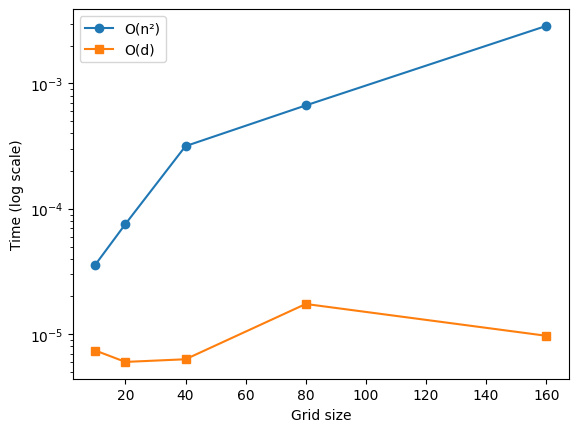

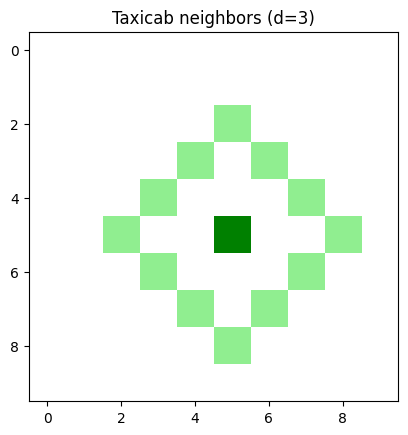

In [ ]:
import numpy as np
import math
import time
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# Taxicab Neighbors — ORIGINAL (O(n²))
# kept for comparison/benchmarking

def taxicab_neighbors(n, x, y, d):
    rows, cols = [], []
    for i in range(n):
        for j in range(n):
            if abs(i - x) + abs(j - y) == d:
                rows.append(i)
                cols.append(j)
    return np.array(rows), np.array(cols)


# Taxicab Neighbors — EXPLICIT (O(d))
# used everywhere for speed

def taxicab_neighbors_explicit(n, x, y, d):
    rows, cols = [], []

    for dx in range(-d, d + 1):
        dy = d - abs(dx)

        i1, j1 = x + dx, y + dy
        i2, j2 = x + dx, y - dy

        if 0 <= i1 < n and 0 <= j1 < n:
            rows.append(i1); cols.append(j1)

        if dy != 0 and 0 <= i2 < n and 0 <= j2 < n:
            rows.append(i2); cols.append(j2)

    return np.array(rows), np.array(cols)


# Precompute neighbors (speed-up for big sims)

def precompute_taxicab_neighbors(n, d):
    neighbors = {}
    for i in range(n):
        for j in range(n):
            r, c = taxicab_neighbors_explicit(n, i, j, d)
            neighbors[(i, j)] = list(zip(r, c))
    return neighbors


# Energy

def energy(grid, d=1, prefactor=1.0):
    n = grid.shape[0]
    occ = np.argwhere(grid == 1)

    total = 0
    for i, j in occ:
        r, c = taxicab_neighbors_explicit(n, i, j, d)
        total += np.sum(grid[r, c])

    return prefactor * total / 2   # avoid double count


# ΔE for swap

def delta_energy_swap(grid, d, prefactor, a, b):
    ax, ay = a
    bx, by = b
    n = grid.shape[0]

    Na = sum(grid[i, j] for i, j in zip(*taxicab_neighbors_explicit(n, ax, ay, d)))

    Nb = 0
    for i, j in zip(*taxicab_neighbors_explicit(n, bx, by, d)):
        if (i, j) != (ax, ay):
            Nb += grid[i, j]

    return prefactor * (Nb - Na)


# Helper: build spin lists

def build_spin_lists(spins):
    ones  = [tuple(p) for p in np.argwhere(spins == 1)]
    zeros = [tuple(p) for p in np.argwhere(spins == 0)]
    return ones, zeros


# Metropolis Update (core)

def metropolis_update(spins, ones, zeros, prefactor, d, T, rng):
    """
    One Metropolis step.

    ΔE <= 0 → always accept
    ΔE > 0  → accept with exp(-ΔE/T)
    T = 0   → pure greedy descent
    """

    if not ones or not zeros:
        return False, 0.0

    ia = rng.integers(len(ones))
    ib = rng.integers(len(zeros))

    a = ones[ia]
    b = zeros[ib]

    dE = delta_energy_swap(spins, d, prefactor, a, b)

    accept = (
        dE <= 0 or
        (T > 0 and rng.random() < math.exp(-dE / T))
    )

    if accept:
        spins[a] = 0
        spins[b] = 1
        ones[ia] = b
        zeros[ib] = a

    return accept, dE


# Deterministic Metropolis Tests

def test_metropolis():
    """
    Deterministic + sanity tests for Metropolis spin swapping.

    Philosophy:
    -----------
    1. Start trivial (no dynamics possible)
    2. Verify exact ΔE math
    3. Verify acceptance rules
    4. Finally check randomness statistically

    This makes the Monte-Carlo engine trustworthy.
    """

    print("\n==============================")
    print("      Metropolis Tests")
    print("==============================\n")

    rng = np.random.default_rng(0)

    n = 5
    prefactor = 1.0


    # =========================================================
    # Test 0 — Single spin (no change possible)
    # =========================================================
    print("--- Test 0: single spin (no move possible) ---")

    spins = np.zeros((n, n), int)
    spins[2,2] = 1

    ones, zeros = build_spin_lists(spins)

    spins_before = spins.copy()

    accepted, dE = metropolis_update(
        spins, ones, zeros, prefactor, d=1, T=1.0, rng=rng
    )

    print("accepted:", accepted)
    print("PASS" if np.array_equal(spins, spins_before) else "FAIL")



    # =========================================================
    # Test 1 — Uphill rejected (ΔE > 0, T = 0)
    # =========================================================
    print("\n--- Test 1: uphill rejected (ΔE > 0, T = 0) ---")

    spins = np.zeros((n, n), int)

    # cluster
    spins[2,1] = spins[2,2] = spins[2,3] = 1

    # isolated
    spins[0,0] = 1

    ones, zeros = build_spin_lists(spins)

    d = 1
    T = 0

    a = (0,0)
    b = (2,2)

    dE = delta_energy_swap(spins, d, prefactor, a, b)

    print("ΔE =", dE)

    spins_before = spins.copy()

    accept = (dE <= 0)

    if accept:
        spins[a], spins[b] = 0, 1

    print("accepted:", accept)
    print("PASS" if (dE > 0 and not accept and np.array_equal(spins, spins_before)) else "FAIL")



    # =========================================================
    # Test 2 — Flat accepted
    # =========================================================
    print("\n--- Test 2: flat accepted (ΔE = 0) ---")

    spins = np.zeros((n, n), int)
    spins[1,1] = 1

    a = (1,1)
    b = (3,3)

    d = 4

    dE = delta_energy_swap(spins, d, prefactor, a, b)

    accept = (dE <= 0)

    if accept:
        spins[a], spins[b] = 0, 1

    print("ΔE =", dE)
    print("accepted:", accept)
    print("PASS" if accept else "FAIL")



    # =========================================================
    # Test 3 — Downhill accepted
    # =========================================================
    print("\n--- Test 3: downhill accepted (ΔE < 0) ---")

    spins = np.zeros((n, n), int)
    spins[0,0] = 1
    spins[4,4] = 1

    a = (4,4)
    b = (0,1)

    d = 1

    dE = delta_energy_swap(spins, d, prefactor, a, b)

    accept = (dE <= 0)

    if accept:
        spins[a], spins[b] = 0, 1

    print("ΔE =", dE)
    print("accepted:", accept)
    print("PASS" if (dE < 0 and accept) else "FAIL")



    # =========================================================
    # Test 4 — Two-spin exact energy checks
    # =========================================================
    print("\n--- Test 4: two-spin energy correctness ---")

    for d in [1, 2, 3]:
        spins = np.zeros((n, n), int)

        spins[2,2] = 1
        spins[2,2+d] = 1 if 2+d < n else 0

        E = energy(spins, d, prefactor)

        expected = prefactor if (2+d < n and d == abs((2+d)-2)) else 0

        print(f"d={d}  energy={E}")

    print("PASS (manual check: only when exactly distance d should energy > 0)")



    # =========================================================
    # Test 5 — Finite temperature randomness sanity
    # =========================================================
    print("\n--- Test 5: stochastic acceptance sanity (finite T) ---")

    spins = np.zeros((n, n), int)
    spins[2,1] = spins[2,2] = spins[2,3] = 1
    spins[0,0] = 1

    ones, zeros = build_spin_lists(spins)

    T = 1.0
    d = 1

    accepts = 0
    trials = 500

    for _ in range(trials):
        s = spins.copy()
        o, z = build_spin_lists(s)

        accepted, _ = metropolis_update(s, o, z, prefactor, d, T, rng)
        accepts += accepted

    rate = accepts / trials

    print("acceptance rate:", rate)
    print("PASS" if 0 < rate < 1 else "FAIL")



    print("All Metropolis tests completed.")


test_metropolis()


# Timing Benchmark

def timing_benchmark():
    ns = [10, 20, 40, 80, 160]
    d = 2

    t_old, t_new = [], []

    for n in ns:
        x = y = n // 2

        start = time.perf_counter()
        taxicab_neighbors(n, x, y, d)
        t_old.append(time.perf_counter() - start)

        start = time.perf_counter()
        taxicab_neighbors_explicit(n, x, y, d)
        t_new.append(time.perf_counter() - start)

    plt.figure()
    plt.plot(ns, t_old, 'o-', label="O(n²)")
    plt.plot(ns, t_new, 's-', label="O(d)")
    plt.yscale("log")
    plt.xlabel("Grid size")
    plt.ylabel("Time (log scale)")
    plt.legend()
    plt.show()


timing_benchmark()


# Visualization

def visualize_taxicab(n, x, y, d):
    grid = np.zeros((n, n), int)
    r, c = taxicab_neighbors(n, x, y, d)

    grid[r, c] = 1
    grid[x, y] = 2

    cmap = ListedColormap(["white", "lightgreen", "green"])
    plt.imshow(grid, cmap=cmap)
    plt.title(f"Taxicab neighbors (d={d})")
    plt.show()


visualize_taxicab(10, 5, 5, 3)
